In [13]:
# Импорты и загрузка данных

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

files = {
    'chelyabinsk': '75_chelyabinsk.csv',
    'kurgan': '37_kurgan.csv',
    'tumen': '71_tumen.csv',
}

date_col = 'date'
target = 'actual_consumption'
region_frames = []

for region_name, filepath in files.items():
  d = pd.read_csv(filepath)
  d = d.loc[:, ~d.columns.str.startswith('Unnamed:')]
  d[date_col] = pd.to_datetime(d[date_col])
  d = (
      d.sort_values(date_col)
      .drop_duplicates(subset=[date_col])
      .set_index(date_col)
  )

  # Регулярная почасовая сетка внутри конкретного региона
  full_idx = pd.date_range(start=d.index.min(), end=d.index.max(), freq='h')
  d = d.reindex(full_idx)
  d.index.name = date_col
  d['region'] = region_name

  d = d[d[target].notna() & (d[target] > 0)].copy()

  # Календарные признаки
  d['hour'] = d.index.hour
  d['dayofweek'] = d.index.dayofweek
  d['is_weekend'] = (d['dayofweek'] >= 5).astype(int)
  d['month'] = d.index.month

  # Лаги и скользящие статистики строго в рамках одного региона
  d['lag_1'] = d[target].shift(1)
  d['lag_24'] = d[target].shift(24)
  d['lag_168'] = d[target].shift(168)
  d['rolling_mean_24'] = d[target].shift(1).rolling(24).mean()
  d['rolling_std_24'] = d[target].shift(1).rolling(24).std()
  d['plan_minus_lag24'] = d['planned_consumption'] - d['lag_24']

  region_frames.append(d)

df = pd.concat(region_frames).sort_index()
df['region_code'] = df['region'].astype('category').cat.codes

features = [
    'region_code',
    'hour',
    'dayofweek',
    'is_weekend',
    'month',
    'lag_1',
    'lag_24',
    'lag_168',
    'rolling_mean_24',
    'rolling_std_24',
    'planned_consumption',
    'actual_generation',
    'planned_generation',
    'plan_minus_lag24',
]

model_df = df.dropna(subset=features + [target]).copy()
print('Итоговый размер датасета:', model_df.shape)
print('Строк по регионам:\n', model_df['region'].value_counts())

Итоговый размер датасета: (120674, 17)
Строк по регионам:
 region
tumen          41486
kurgan         39641
chelyabinsk    39547
Name: count, dtype: int64


In [15]:
import pandas as pd

files = {
    'chelyabinsk': '75_chelyabinsk.csv',
    'kurgan': '37_kurgan.csv',
    'tumen': '71_tumen.csv',
}

for name, path in files.items():
  sample = pd.read_csv(path, nrows=2)
  print(f'=== {name} ({path}) ===')
  print('Колонки:', list(sample.columns))
  print(sample.head(1).T)

=== chelyabinsk (75_chelyabinsk.csv) ===
Колонки: ['date', 'planned_consumption', 'actual_consumption', 'planned_generation', 'actual_generation', 'average_price']
                                       0
date                 2022-01-01 00:00:00
planned_consumption                 4076
actual_consumption                  4051
planned_generation                  3344
actual_generation                   3332
average_price                        935
=== kurgan (37_kurgan.csv) ===
Колонки: ['Unnamed: 0', 'planned_consumption', 'actual_consumption', 'planned_generation', 'actual_generation', 'average_price', 'date']
                                       0
Unnamed: 0                             0
planned_consumption                  509
actual_consumption                   500
planned_generation                   488
actual_generation                    484
average_price                        903
date                 2022-01-01 00:00:00
=== tumen (71_tumen.csv) ===
Колонки: ['date', 'plann

In [7]:
test_days = 15
retrain_step = 3  # переобучаем модель каждые 3 дня (в 3 раза реже)
unique_days = model_df.index.normalize().unique()

if len(unique_days) <= test_days:
  raise ValueError('Недостаточно дней для выбранного окна теста.')

test_day_list = unique_days[-test_days:]
test_parts = []
rf_model = None

for i, current_day in enumerate(test_day_list):
  if i % retrain_step == 0 or rf_model is None:
    train_mask = model_df.index < current_day
    X_train = model_df.loc[train_mask, features]
    y_train = model_df.loc[train_mask, target]

    rf_model = RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1,
    )
    rf_model.fit(X_train, y_train)

  test_mask = model_df.index.normalize() == current_day
  X_test = model_df.loc[test_mask, features]

  day_eval = model_df.loc[
      test_mask, [target, 'planned_consumption', 'hour', 'region']
  ].copy()
  day_eval['date'] = day_eval.index.date
  day_eval['pred'] = rf_model.predict(X_test)
  day_eval['score'] = 0.7 * day_eval['pred'] + 0.3 * day_eval['planned_consumption']
  test_parts.append(day_eval)

test_df = pd.concat(test_parts).sort_index()
last_model = rf_model

mae = mean_absolute_error(test_df[target], test_df['pred'])
rmse = np.sqrt(mean_squared_error(test_df[target], test_df['pred']))
r2 = r2_score(test_df[target], test_df['pred'])
print(f'Регрессия (по pred): MAE = {mae:.2f} | RMSE = {rmse:.2f} | R2 = {r2:.4f}')


Регрессия (по pred): MAE = 39.13 | RMSE = 54.30 | R2 = 0.9998


In [8]:
def evaluate_peak_hours(df_eval: pd.DataFrame, col_name: str, k_list=(1, 3, 5)):
  tmp = df_eval.reset_index(drop=True)
  results = {k: [] for k in k_list}
  hour_errors = []

  for _, day_group in tmp.groupby(['region', 'date'], sort=False):
    true_top1_hour = int(day_group.nlargest(1, target)['hour'].iloc[0])
    pred_top1_hour = int(day_group.nlargest(1, col_name)['hour'].iloc[0])
    hour_errors.append(abs(true_top1_hour - pred_top1_hour))

    for k in k_list:
      true_hours = set(day_group.nlargest(k, target)['hour'])
      pred_hours = set(day_group.nlargest(k, col_name)['hour'])
      hit = 1.0 if (true_hours & pred_hours) else 0.0
      results[k].append(hit)

  summary = {f'Top-{k}': np.mean(results[k]) * 100 for k in k_list}
  summary['Mean_Top1_Hour_Diff'] = np.mean(hour_errors)
  return summary


for col in ['pred', 'score']:
  res = evaluate_peak_hours(test_df, col)
  print(
      f'Пики по [{col}]: '
      f"Top-1 = {res['Top-1']:.2f}% | "
      f"Top-3 = {res['Top-3']:.2f}% | "
      f"Top-5 = {res['Top-5']:.2f}% | "
      f"Средняя разница пикового часа = {res['Mean_Top1_Hour_Diff']:.2f} ч"
  )

Пики по [pred]: Top-1 = 29.03% | Top-3 = 90.32% | Top-5 = 100.00% | Средняя разница пикового часа = 1.65 ч
Пики по [score]: Top-1 = 25.81% | Top-3 = 93.55% | Top-5 = 100.00% | Средняя разница пикового часа = 1.71 ч


/tmp/ipykernel_1129/4139796954.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  true_peaks = tmp.groupby('date', group_keys=False).apply(
/tmp/ipykernel_1129/4139796954.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pred_peaks = tmp.groupby('date', group_keys=False).apply(


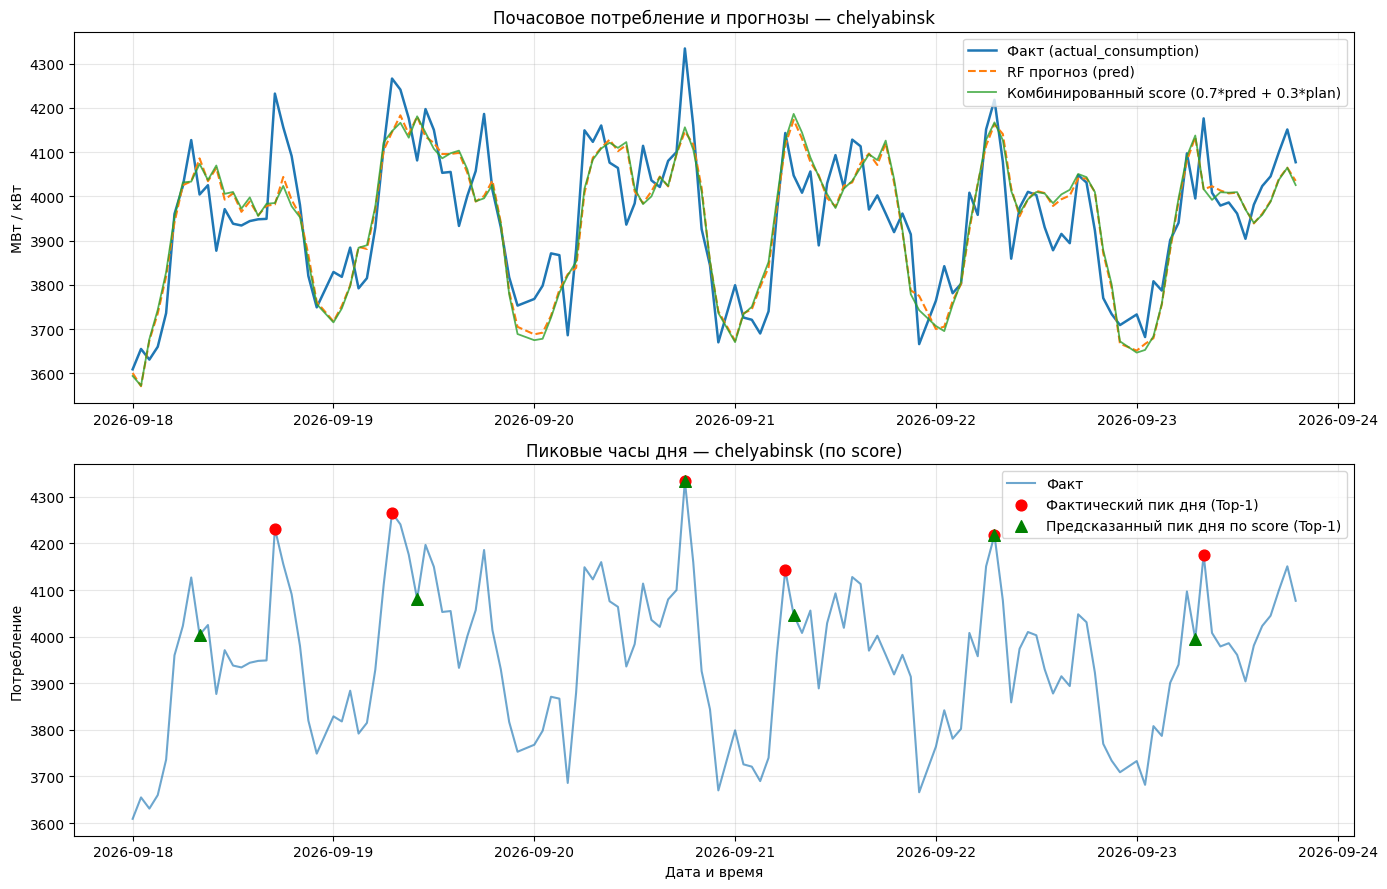

In [9]:
plot_region = 'chelyabinsk'  # 'chelyabinsk', 'kurgan' или 'tumen'
plot_col = 'score'  # 'score' или 'pred'

reg_df = test_df[test_df['region'] == plot_region].copy()
x_time = reg_df.index
tmp = reg_df.reset_index(drop=True)
tmp['dt'] = x_time

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=False)

axes[0].plot(
    tmp['dt'], tmp[target], label='Факт (actual_consumption)', linewidth=1.8
)
axes[0].plot(
    tmp['dt'],
    tmp['pred'],
    label='RF прогноз (pred)',
    linewidth=1.5,
    linestyle='--',
)
axes[0].plot(
    tmp['dt'],
    tmp['score'],
    label='Комбинированный score (0.7*pred + 0.3*plan)',
    linewidth=1.3,
    alpha=0.8,
)
axes[0].set_title(f'Почасовое потребление и прогнозы — {plot_region}')
axes[0].set_ylabel('МВт / кВт')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

true_peaks = tmp.groupby('date', group_keys=False).apply(
    lambda g: g.nlargest(1, target)
)
pred_peaks = tmp.groupby('date', group_keys=False).apply(
    lambda g: g.nlargest(1, plot_col)
)

axes[1].plot(tmp['dt'], tmp[target], label='Факт', color='tab:blue', alpha=0.65)
axes[1].scatter(
    true_peaks['dt'],
    true_peaks[target],
    color='red',
    s=60,
    zorder=5,
    label='Фактический пик дня (Top-1)',
)
axes[1].scatter(
    pred_peaks['dt'],
    pred_peaks[target],
    color='green',
    marker='^',
    s=70,
    zorder=6,
    label=f'Предсказанный пик дня по {plot_col} (Top-1)',
)
axes[1].set_title(f'Пиковые часы дня — {plot_region} (по {plot_col})')
axes[1].set_ylabel('Потребление')
axes[1].set_xlabel('Дата и время')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
#Важность признаков (опционально)
if last_model is not None:
  importances = pd.Series(
      last_model.feature_importances_, index=features
  ).sort_values(ascending=False)
  display(importances.round(4))

,0
lag_168,0.1727
lag_1,0.1546
planned_generation,0.1421
planned_consumption,0.1391
rolling_mean_24,0.1338
region_code,0.1254
lag_24,0.1086
rolling_std_24,0.0181
actual_generation,0.0056
hour,0.0000


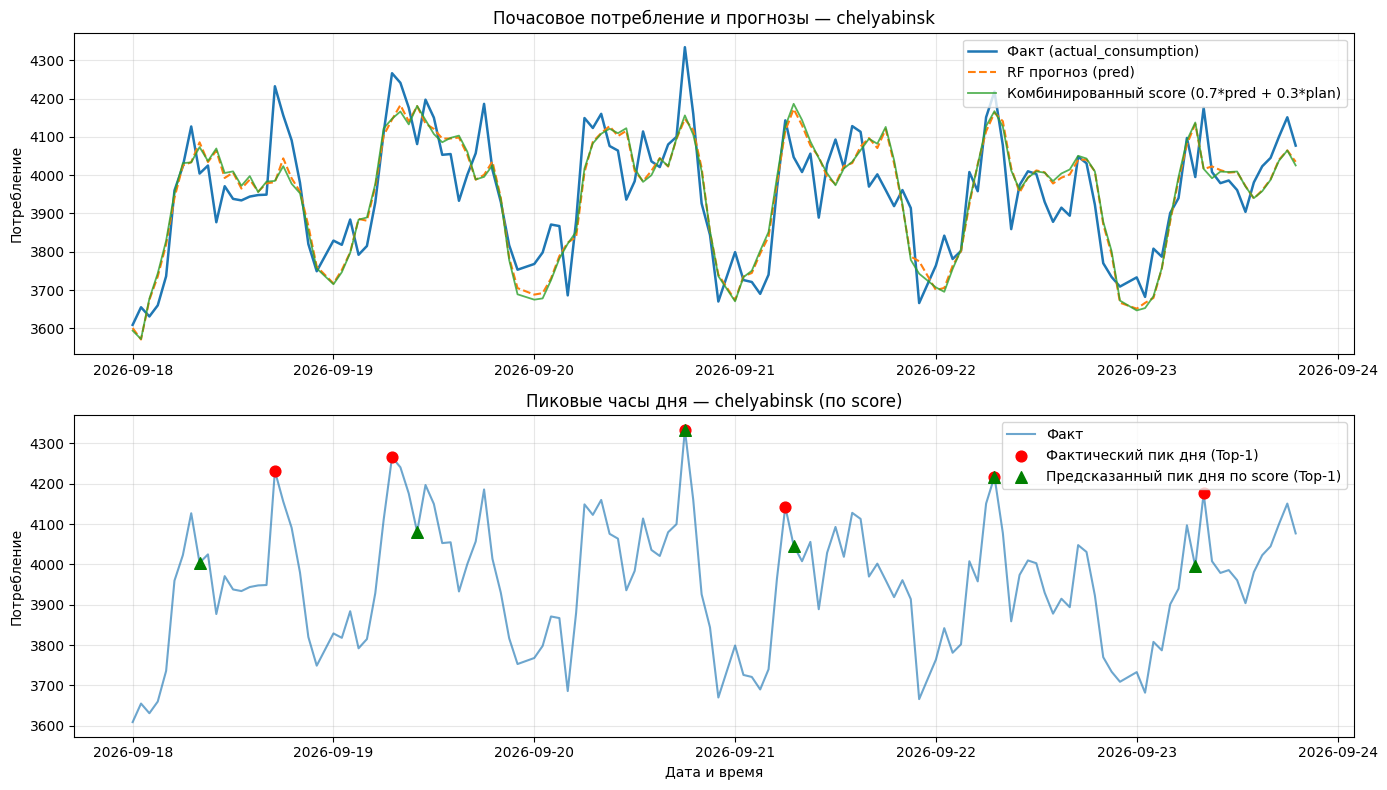

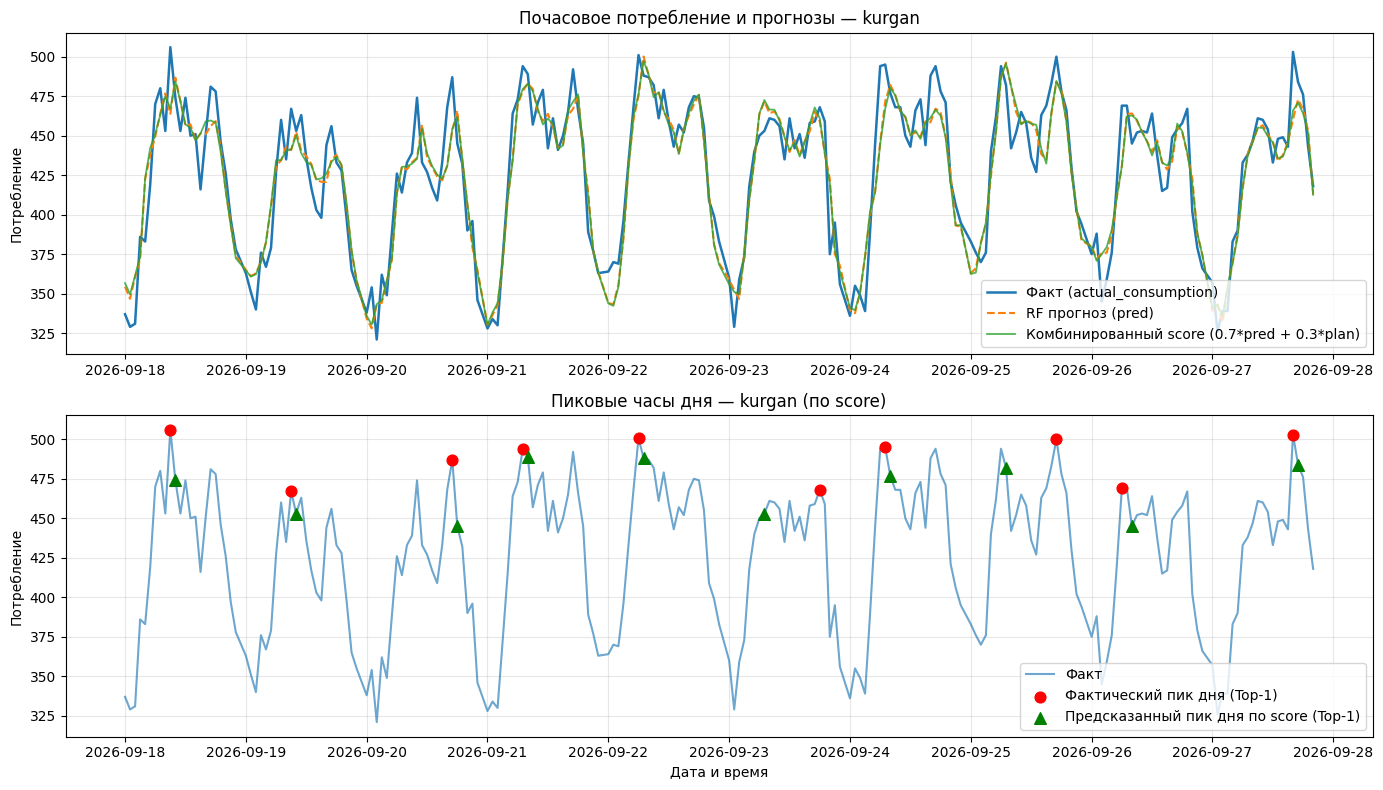

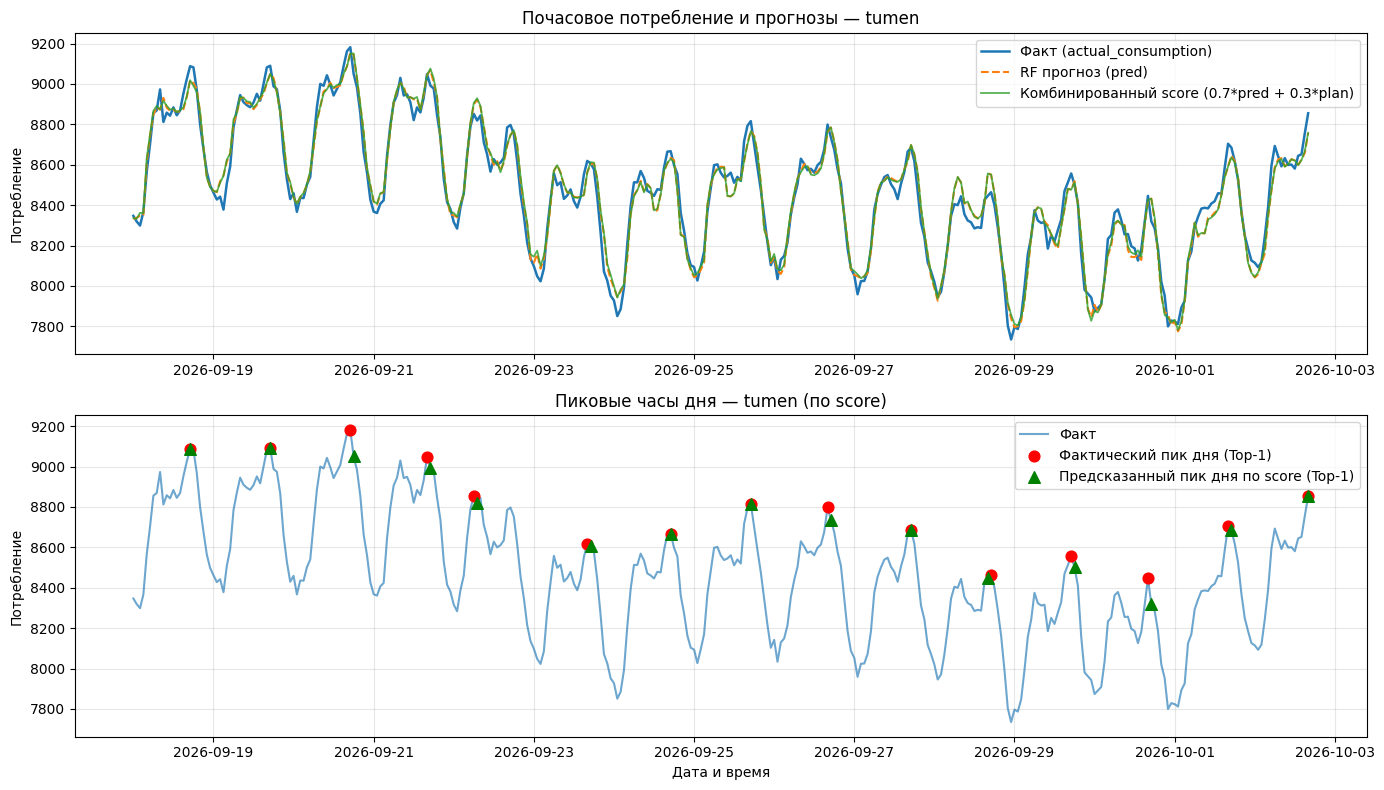

     region metric_col   MAE  RMSE     R2  Top-1_%  Top-3_%  Top-5_%  Hour_Diff
chelyabinsk       pred 67.96 84.04 0.6997     33.3     83.3    100.0       2.00
chelyabinsk      score 67.96 84.04 0.6997     33.3     83.3    100.0       2.33
     kurgan       pred 13.58 16.90 0.8694      0.0     80.0    100.0       3.00
     kurgan      score 13.58 16.90 0.8694      0.0     90.0    100.0       3.00
      tumen       pred 44.60 55.63 0.9684     46.7    100.0    100.0       0.60
      tumen      score 44.60 55.63 0.9684     40.0    100.0    100.0       0.60


In [11]:
plot_col = 'score'  # 'score' или 'pred'
rows = []


def get_daily_top1_rows(df_part: pd.DataFrame, value_col: str) -> pd.DataFrame:
  peak_indices = []
  for _, g in df_part.groupby('date', sort=False):
    peak_indices.append(g[value_col].idxmax())
  return df_part.loc[peak_indices]


for reg in sorted(test_df['region'].unique()):
  sub = test_df[test_df['region'] == reg].copy()
  if sub.empty:
    continue

  x_time = sub.index
  tmp = sub.reset_index(drop=True)
  tmp['dt'] = x_time

  mae_r = mean_absolute_error(tmp[target], tmp['pred'])
  rmse_r = np.sqrt(mean_squared_error(tmp[target], tmp['pred']))
  r2_r = r2_score(tmp[target], tmp['pred'])

  for col in ['pred', 'score']:
    res = evaluate_peak_hours(tmp, col)
    rows.append({
        'region': reg,
        'metric_col': col,
        'MAE': round(mae_r, 2),
        'RMSE': round(rmse_r, 2),
        'R2': round(r2_r, 4),
        'Top-1_%': round(res['Top-1'], 1),
        'Top-3_%': round(res['Top-3'], 1),
        'Top-5_%': round(res['Top-5'], 1),
        'Hour_Diff': round(res['Mean_Top1_Hour_Diff'], 2),
    })

  true_peaks = get_daily_top1_rows(tmp, target)
  pred_peaks = get_daily_top1_rows(tmp, plot_col)

  fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

  axes[0].plot(
      tmp['dt'], tmp[target], label='Факт (actual_consumption)', linewidth=1.8
  )
  axes[0].plot(
      tmp['dt'],
      tmp['pred'],
      label='RF прогноз (pred)',
      linewidth=1.5,
      linestyle='--',
  )
  axes[0].plot(
      tmp['dt'],
      tmp['score'],
      label='Комбинированный score (0.7*pred + 0.3*plan)',
      linewidth=1.3,
      alpha=0.8,
  )
  axes[0].set_title(f'Почасовое потребление и прогнозы — {reg}')
  axes[0].set_ylabel('Потребление')
  axes[0].legend()
  axes[0].grid(True, alpha=0.3)

  axes[1].plot(
      tmp['dt'], tmp[target], label='Факт', color='tab:blue', alpha=0.65
  )
  axes[1].scatter(
      true_peaks['dt'],
      true_peaks[target],
      color='red',
      s=60,
      zorder=5,
      label='Фактический пик дня (Top-1)',
  )
  axes[1].scatter(
      pred_peaks['dt'],
      pred_peaks[target],
      color='green',
      marker='^',
      s=70,
      zorder=6,
      label=f'Предсказанный пик дня по {plot_col} (Top-1)',
  )
  axes[1].set_title(f'Пиковые часы дня — {reg} (по {plot_col})')
  axes[1].set_ylabel('Потребление')
  axes[1].set_xlabel('Дата и время')
  axes[1].legend()
  axes[1].grid(True, alpha=0.3)

  plt.tight_layout()
  plt.show()

summary_by_region = pd.DataFrame(rows)
print(summary_by_region.to_string(index=False))

In [12]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# 1. Четыре датасета (при необходимости замени 94_udmurtya.csv на 33_kyrov.csv)
files_4 = {
    'chelyabinsk': '75_chelyabinsk.csv',
    'kurgan': '37_kurgan.csv',
    'tumen': '71_tumen.csv',
    'udmurtya': '94_udmurtya.csv',
}

date_col = 'date'
target = 'actual_consumption'
frames_4 = []

for reg_name, path in files_4.items():
  d = pd.read_csv(path)
  d = d.loc[:, ~d.columns.str.startswith('Unnamed:')]
  d[date_col] = pd.to_datetime(d[date_col])
  d = (
      d.sort_values(date_col)
      .drop_duplicates(subset=[date_col])
      .set_index(date_col)
  )

  full_idx = pd.date_range(start=d.index.min(), end=d.index.max(), freq='h')
  d = d.reindex(full_idx)
  d.index.name = date_col
  d['region'] = reg_name

  d = d[d[target].notna() & (d[target] > 0)].copy()

  d['hour'] = d.index.hour
  d['dayofweek'] = d.index.dayofweek
  d['is_weekend'] = (d['dayofweek'] >= 5).astype(int)
  d['month'] = d.index.month

  d['lag_1'] = d[target].shift(1)
  d['lag_24'] = d[target].shift(24)
  d['lag_168'] = d[target].shift(168)
  d['rolling_mean_24'] = d[target].shift(1).rolling(24).mean()
  d['rolling_std_24'] = d[target].shift(1).rolling(24).std()
  d['plan_minus_lag24'] = d['planned_consumption'] - d['lag_24']

  frames_4.append(d)

df_4 = pd.concat(frames_4).sort_index()
df_4['region_code'] = df_4['region'].astype('category').cat.codes

features_4 = [
    'region_code',
    'hour',
    'dayofweek',
    'is_weekend',
    'month',
    'lag_1',
    'lag_24',
    'lag_168',
    'rolling_mean_24',
    'rolling_std_24',
    'planned_consumption',
    'actual_generation',
    'planned_generation',
    'plan_minus_lag24',
]

model_df_4 = df_4.dropna(subset=features_4 + [target]).copy()

# 2. Обучение на 4 датасетах и прогноз для chelyabinsk на последний доступный день
chely_days = (
    model_df_4[model_df_4['region'] == 'chelyabinsk'].index.normalize().unique()
)
target_day = chely_days[-1]  # при необходимости задай дату вручную, например pd.Timestamp('2026-09-28')

train_mask = model_df_4.index < target_day
test_mask = (model_df_4['region'] == 'chelyabinsk') & (
    model_df_4.index.normalize() == target_day
)

X_train = model_df_4.loc[train_mask, features_4]
y_train = model_df_4.loc[train_mask, target]
X_chely_day = model_df_4.loc[test_mask, features_4]

rf_4 = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
rf_4.fit(X_train, y_train)

forecast_day = model_df_4.loc[
    test_mask, ['hour', 'planned_consumption', target]
].copy()
forecast_day['pred'] = rf_4.predict(X_chely_day)
forecast_day['score'] = (
    0.7 * forecast_day['pred'] + 0.3 * forecast_day['planned_consumption']
)

# 3. Вывод 3 пиковых часов в сутках
top3_peaks = forecast_day.nlargest(3, 'score').copy()
top3_hours_sorted = sorted(top3_peaks['hour'].astype(int).tolist())

print(f'Регион: chelyabinsk | Дата прогноза: {target_day.date()}')
print('3 пиковых часа в сутках (по возрастанию часа):', top3_hours_sorted)
print('\nДетализация по топ-3 часам (ранжировано по score):')
print(
    top3_peaks[['hour', 'score', 'pred', 'planned_consumption', target]]
    .round(2)
    .to_string(index=True)
)

Регион: chelyabinsk | Дата прогноза: 2026-09-23
3 пиковых часа в сутках (по возрастанию часа): [6, 7, 18]

Детализация по топ-3 часам (ранжировано по score):
                     hour    score     pred  planned_consumption  actual_consumption
date                                                                                
2026-09-23 07:00:00     7  4137.61  4134.02               4146.0              3995.0
2026-09-23 06:00:00     6  4093.62  4084.88               4114.0              4097.0
2026-09-23 18:00:00    18  4060.14  4058.49               4064.0              4151.0


Сравнение пиковых часов — chelyabinsk (2026-09-23)
Прогноз ТОП-1..3 (по score): [7, 6, 18]
Факт ТОП-1..3 (по факту):   [8, 18, 17]

Детализация по прогнозным ТОП-1..3:
 rank  hour   score    pred  planned_consumption  actual_consumption
ТОП-1     7 4137.61 4134.02               4146.0              3995.0
ТОП-2     6 4093.62 4084.88               4114.0              4097.0
ТОП-3    18 4060.14 4058.49               4064.0              4151.0

Детализация по фактическим ТОП-1..3:
 rank  hour  actual_consumption   score    pred  planned_consumption
ТОП-1     8              4176.0 4018.71 4019.45               4017.0
ТОП-2    18              4151.0 4060.14 4058.49               4064.0
ТОП-3    17              4100.0 4037.69 4040.13               4032.0


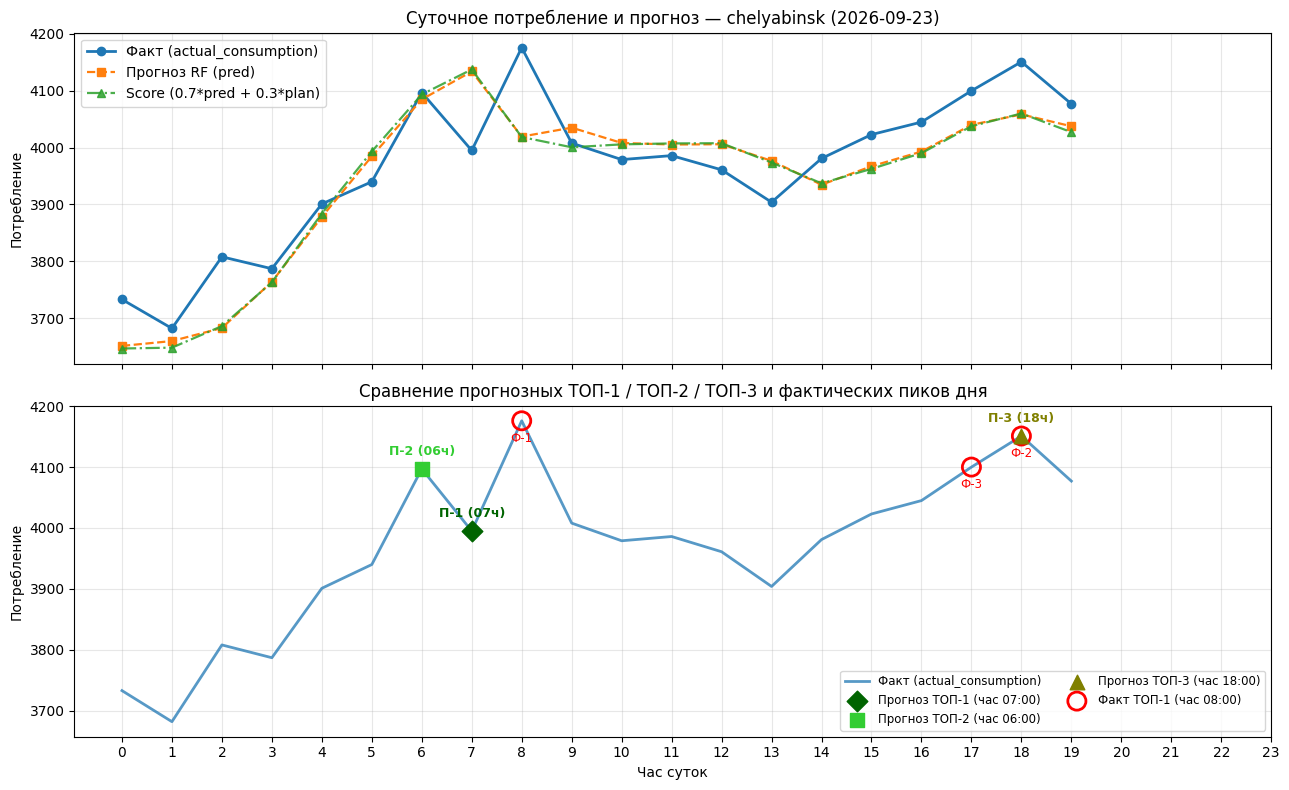

In [16]:
import matplotlib.pyplot as plt

# 1. Формируем таблицы ТОП-1, ТОП-2, ТОП-3 по прогнозу (score) и по факту (actual_consumption)
pred_top3 = forecast_day.nlargest(3, 'score').copy()
pred_top3['rank'] = ['ТОП-1', 'ТОП-2', 'ТОП-3']

true_top3 = forecast_day.nlargest(3, target).copy()
true_top3['rank'] = ['ТОП-1', 'ТОП-2', 'ТОП-3']

# Объединяем по часу (hour) для прямого сравнения в одной таблице
cmp_df = (
    forecast_day.reset_index()
    .assign(hour_int=lambda df: df['hour'].astype(int))
    .set_index('hour_int')
)

pred_rank_map = {int(r['hour']): rk for rk, (_, r) in zip(pred_top3['rank'], pred_top3.iterrows())}
true_rank_map = {int(r['hour']): rk for rk, (_, r) in zip(true_top3['rank'], true_top3.iterrows())}

print(f"Сравнение пиковых часов — chelyabinsk ({target_day.date()})")
print("Прогноз ТОП-1..3 (по score):", [int(h) for h in pred_top3['hour']])
print("Факт ТОП-1..3 (по факту):  ", [int(h) for h in true_top3['hour']])
print("\nДетализация по прогнозным ТОП-1..3:")
print(
    pred_top3[['rank', 'hour', 'score', 'pred', 'planned_consumption', target]]
    .round(2)
    .to_string(index=False)
)
print("\nДетализация по фактическим ТОП-1..3:")
print(
    true_top3[['rank', 'hour', target, 'score', 'pred', 'planned_consumption']]
    .round(2)
    .to_string(index=False)
)

# 2. График суточного профиля с ТОП-1, ТОП-2, ТОП-3
hours = forecast_day['hour'].astype(int)
y_true = forecast_day[target]
y_pred = forecast_day['pred']
y_score = forecast_day['score']

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# Верхний график: факт, прогноз RF и комбинированный score
axes[0].plot(hours, y_true, marker='o', linewidth=2, label='Факт (actual_consumption)')
axes[0].plot(hours, y_pred, marker='s', linestyle='--', linewidth=1.6, label='Прогноз RF (pred)')
axes[0].plot(hours, y_score, marker='^', linestyle='-.', linewidth=1.6, alpha=0.85, label='Score (0.7*pred + 0.3*plan)')
axes[0].set_title(f'Суточное потребление и прогноз — chelyabinsk ({target_day.date()})')
axes[0].set_ylabel('Потребление')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Нижний график: сравнение ТОП-1, ТОП-2, ТОП-3 (прогноз vs факт)
axes[1].plot(hours, y_true, color='tab:blue', linewidth=2, alpha=0.75, label='Факт (actual_consumption)')

markers = ['D', 's', '^']
colors_pred = ['darkgreen', 'limegreen', 'olive']
for idx, (_, row) in enumerate(pred_top3.iterrows()):
    h_val = int(row['hour'])
    axes[1].scatter(
        h_val,
        row[target],
        color=colors_pred[idx],
        marker=markers[idx],
        s=110,
        zorder=6,
        label=f"Прогноз {pred_top3['rank'].iloc[idx]} (час {h_val:02d}:00)",
    )
    axes[1].annotate(
        f"П-{idx+1} ({h_val:02d}ч)",
        (h_val, row[target]),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=9,
        fontweight='bold',
        color=colors_pred[idx],
    )

for idx, (_, row) in enumerate(true_top3.iterrows()):
    h_val = int(row['hour'])
    axes[1].scatter(
        h_val,
        row[target],
        facecolors='none',
        edgecolors='red',
        linewidths=2,
        s=170,
        zorder=5,
        label=f"Факт {true_top3['rank'].iloc[idx]} (час {h_val:02d}:00)" if idx == 0 else None,
    )
    axes[1].annotate(
        f"Ф-{idx+1}",
        (h_val, row[target]),
        textcoords="offset points",
        xytext=(0, -15),
        ha='center',
        fontsize=8.5,
        color='red',
    )

axes[1].set_title('Сравнение прогнозных ТОП-1 / ТОП-2 / ТОП-3 и фактических пиков дня')
axes[1].set_xlabel('Час суток')
axes[1].set_ylabel('Потребление')
axes[1].set_xticks(range(0, 24))
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='best', ncol=2, fontsize=8.5)

plt.tight_layout()
plt.show()

In [17]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_days = 15
retrain_step = 3

chely_only_df = model_df_4[model_df_4['region'] == 'chelyabinsk'].copy()
chely_days = chely_only_df.index.normalize().unique()

if len(chely_days) <= test_days:
  raise ValueError('Недостаточно дней в chelyabinsk для окна теста.')

eval_days = chely_days[-test_days:]


def run_chely_rolling_eval(
    train_source_df: pd.DataFrame, feat_cols: list, label: str
) -> pd.DataFrame:
  parts = []
  model = None

  for i, current_day in enumerate(eval_days):
    if i % retrain_step == 0 or model is None:
      tr_mask = train_source_df.index < current_day
      X_tr = train_source_df.loc[tr_mask, feat_cols]
      y_tr = train_source_df.loc[tr_mask, target]

      model = RandomForestRegressor(
          n_estimators=100,
          max_depth=12,
          min_samples_leaf=3,
          random_state=42,
          n_jobs=-1,
      )
      model.fit(X_tr, y_tr)

    te_mask = chely_only_df.index.normalize() == current_day
    X_te = chely_only_df.loc[te_mask, feat_cols]

    day_res = chely_only_df.loc[
        te_mask, [target, 'planned_consumption', 'hour']
    ].copy()
    day_res['date_str'] = day_res.index.date
    day_res['pred'] = model.predict(X_te)
    day_res['score'] = (
        0.7 * day_res['pred'] + 0.3 * day_res['planned_consumption']
    )
    day_res['approach'] = label
    parts.append(day_res.reset_index(drop=True))

  return pd.concat(parts, ignore_index=True)


# Для локальной модели убираем region_code, так как регион один
local_features = [c for c in features_4 if c != 'region_code']

res_local = run_chely_rolling_eval(
    chely_only_df, local_features, 'Local (только Челябинск)'
)
res_spatial = run_chely_rolling_eval(
    model_df_4, features_4, 'Spatial (4 региона)'
)


def calc_chely_metrics(df_res: pd.DataFrame) -> list:
  out = []
  mae_v = mean_absolute_error(df_res[target], df_res['pred'])
  rmse_v = np.sqrt(mean_squared_error(df_res[target], df_res['pred']))
  r2_v = r2_score(df_res[target], df_res['pred'])

  for col in ['pred', 'score']:
    top1_hits, top3_hits, top5_hits, hour_diffs = [], [], [], []
    # Доля дней, где совпали все 3 часа из Топ-3 (строгое попадание 3 из 3) и хотя бы 1 из Топ-3
    top3_any_hits = []
    top3_recall_list = []

    for _, g in df_res.groupby('date_str', sort=False):
      true_top1 = int(g.nlargest(1, target)['hour'].iloc[0])
      pred_top1 = int(g.nlargest(1, col)['hour'].iloc[0])
      hour_diffs.append(abs(true_top1 - pred_top1))

      t1 = set(g.nlargest(1, target)['hour'])
      p1 = set(g.nlargest(1, col)['hour'])
      top1_hits.append(1.0 if (t1 & p1) else 0.0)

      t3 = set(g.nlargest(3, target)['hour'])
      p3 = set(g.nlargest(3, col)['hour'])
      top3_any_hits.append(1.0 if (t3 & p3) else 0.0)
      top3_recall_list.append(len(t3 & p3) / 3.0)

      t5 = set(g.nlargest(5, target)['hour'])
      p5 = set(g.nlargest(5, col)['hour'])
      top5_hits.append(1.0 if (t5 & p5) else 0.0)

    out.append({
        'Подход': df_res['approach'].iloc[0],
        'Ранжирование': col,
        'MAE': round(mae_v, 2),
        'RMSE': round(rmse_v, 2),
        'R2': round(r2_v, 4),
        'Top1_пик_%': round(np.mean(top1_hits) * 100, 1),
        'Top3_хотя_бы_1_%': round(np.mean(top3_any_hits) * 100, 1),
        'Top3_доля_совп_%': round(np.mean(top3_recall_list) * 100, 1),
        'Top5_хотя_бы_1_%': round(np.mean(top5_hits) * 100, 1),
        'Сдвиг_пика_ч': round(np.mean(hour_diffs), 2),
    })
  return out


comparison_table = pd.DataFrame(
    calc_chely_metrics(res_local) + calc_chely_metrics(res_spatial)
)
print('Сравнение на тестовом окне (15 дней) для chelyabinsk:')
print(comparison_table.to_string(index=False))

Сравнение на тестовом окне (15 дней) для chelyabinsk:
                  Подход Ранжирование   MAE  RMSE     R2  Top1_пик_%  Top3_хотя_бы_1_%  Top3_доля_совп_%  Top5_хотя_бы_1_%  Сдвиг_пика_ч
Local (только Челябинск)         pred 68.96 85.26 0.7986        20.0              73.3              31.1              93.3          2.73
Local (только Челябинск)        score 68.96 85.26 0.7986        20.0              73.3              33.3              93.3          3.13
     Spatial (4 региона)         pred 68.69 85.06 0.7996        20.0              80.0              35.6              93.3          2.87
     Spatial (4 региона)        score 68.69 85.06 0.7996        13.3              73.3              33.3              93.3          3.53


In [18]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_days = 15
retrain_step = 3
local_features = [c for c in features_4 if c != 'region_code']

all_rows = []

for reg_name in ['chelyabinsk', 'kurgan', 'tumen', 'udmurtya']:
  reg_df = model_df_4[model_df_4['region'] == reg_name].copy()
  reg_days = reg_df.index.normalize().unique()
  eval_days = reg_days[-test_days:]

  parts = []
  model = None
  for i, current_day in enumerate(eval_days):
    if i % retrain_step == 0 or model is None:
      tr_mask = reg_df.index < current_day
      model = RandomForestRegressor(
          n_estimators=100,
          max_depth=12,
          min_samples_leaf=3,
          random_state=42,
          n_jobs=-1,
      )
      model.fit(
          reg_df.loc[tr_mask, local_features], reg_df.loc[tr_mask, target]
      )

    te_mask = reg_df.index.normalize() == current_day
    day_res = reg_df.loc[
        te_mask, [target, 'planned_consumption', 'hour']
    ].copy()
    day_res['date_str'] = day_res.index.date
    day_res['pred'] = model.predict(reg_df.loc[te_mask, local_features])
    day_res['score'] = (
        0.7 * day_res['pred'] + 0.3 * day_res['planned_consumption']
    )
    parts.append(day_res.reset_index(drop=True))

  df_res = pd.concat(parts, ignore_index=True)
  mae_v = mean_absolute_error(df_res[target], df_res['pred'])
  rmse_v = np.sqrt(mean_squared_error(df_res[target], df_res['pred']))
  r2_v = r2_score(df_res[target], df_res['pred'])

  for col in ['pred', 'score']:
    top1_hits, top3_any, top3_rec, top5_any, diffs = [], [], [], [], []
    for _, g in df_res.groupby('date_str', sort=False):
      true_top1 = int(g.nlargest(1, target)['hour'].iloc[0])
      pred_top1 = int(g.nlargest(1, col)['hour'].iloc[0])
      diffs.append(abs(true_top1 - pred_top1))

      t1, p1 = set(g.nlargest(1, target)['hour']), set(
          g.nlargest(1, col)['hour']
      )
      t3, p3 = set(g.nlargest(3, target)['hour']), set(
          g.nlargest(3, col)['hour']
      )
      t5, p5 = set(g.nlargest(5, target)['hour']), set(
          g.nlargest(5, col)['hour']
      )

      top1_hits.append(1.0 if (t1 & p1) else 0.0)
      top3_any.append(1.0 if (t3 & p3) else 0.0)
      top3_rec.append(len(t3 & p3) / 3.0)
      top5_any.append(1.0 if (t5 & p5) else 0.0)

    all_rows.append({
        'Регион': reg_name,
        'Подход': 'Local',
        'Критерий': col,
        'MAE': round(mae_v, 2),
        'RMSE': round(rmse_v, 2),
        'R2': round(r2_v, 4),
        'Top1_%': round(np.mean(top1_hits) * 100, 1),
        'Top3_>=1_%': round(np.mean(top3_any) * 100, 1),
        'Top3_совп_%': round(np.mean(top3_rec) * 100, 1),
        'Top5_>=1_%': round(np.mean(top5_any) * 100, 1),
        'Сдвиг_ч': round(np.mean(diffs), 2),
    })

print(pd.DataFrame(all_rows).to_string(index=False))

     Регион Подход Критерий   MAE  RMSE     R2  Top1_%  Top3_>=1_%  Top3_совп_%  Top5_>=1_%  Сдвиг_ч
chelyabinsk  Local     pred 68.96 85.26 0.7986    20.0        73.3         31.1        93.3     2.73
chelyabinsk  Local    score 68.96 85.26 0.7986    20.0        73.3         33.3        93.3     3.13
     kurgan  Local     pred 12.99 16.38 0.8843     0.0        80.0         37.8       100.0     3.47
     kurgan  Local    score 12.99 16.38 0.8843     0.0        80.0         37.8       100.0     3.67
      tumen  Local     pred 44.45 55.11 0.9690    46.7       100.0         80.0       100.0     0.53
      tumen  Local    score 44.45 55.11 0.9690    40.0       100.0         77.8       100.0     0.60
   udmurtya  Local     pred 16.89 21.29 0.9645    20.0        93.3         55.6       100.0     2.20
   udmurtya  Local    score 16.89 21.29 0.9645    20.0       100.0         55.6       100.0     2.33
